In [1]:
import numpy as np
import pandas as pd
import glob
from sklearn.preprocessing import StandardScaler

def load_and_preprocess_dataset(file_pattern="*.csv", window_size=104, overlap=0.5):
    """
    Loads participant CSV files from the chest-mounted accelerometer dataset,
    filters noise/unlabelled data, normalizes features, and creates sliding windows.

    Parameters:
    - file_pattern (str): Glob pattern to find participant CSV files.
    - window_size (int): Number of time steps per window (e.g., 104 steps ≈ 2 seconds at 52Hz).
    - overlap (float): Overlap ratio between consecutive windows (0.5 for 50%).

    Returns:
    - X_all (np.ndarray): Tensor of shape (total_windows, window_size, 3)
    - y_all (np.ndarray): Corresponding activity labels for each window
    """
    all_windows = []
    all_labels = []

    scaler = StandardScaler()
    csv_files = glob.glob(file_pattern)

    print(f"Found {len(csv_files)} participant files. Processing...")

    for file in csv_files:
        # Load CSV without header (columns: seq, acc_x, acc_y, acc_z, label)
        df = pd.read_csv(file, header=None)
        df.columns = ['seq', 'acc_x', 'acc_y', 'acc_z', 'label']

        # Filter out label 0 (unlabelled transitional data)
        df = df[df['label'] != 0].reset_index(drop=True)
        if len(df) < window_size:
            continue

        # Extract features (x, y, z acceleration) and labels
        feature_cols = ['acc_x', 'acc_y', 'acc_z']
        scaled_features = scaler.fit_transform(df[feature_cols])
        labels = df['label'].values

        step_size = int(window_size * (1 - overlap))

        # Sliding window segmentation
        for i in range(0, len(scaled_features) - window_size + 1, step_size):
            window = scaled_features[i : i + window_size]
            window_labels = labels[i : i + window_size]

            # Use the dominant (most frequent) label in the window
            dominant_label = np.bincount(window_labels).argmax()

            all_windows.append(window)
            all_labels.append(dominant_label)

    return np.array(all_windows), np.array(all_labels)

# --- Execute Preprocessing ---
# At 52 Hz, a window size of 104 represents roughly 2 seconds of motion data.
X, y = load_and_preprocess_dataset("*.csv", window_size=104, overlap=0.5)

print(f"\nFinal Preprocessed Tensors:")
print(f"X shape (Input Tensor): {X.shape}") # Expected: (Num_Windows, 104, 3)
print(f"y shape (Labels): {y.shape}")       # Expected: (Num_Windows,)

Found 15 participant files. Processing...

Final Preprocessed Tensors:
X shape (Input Tensor): (36961, 104, 3)
y shape (Labels): (36961,)


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, BatchNormalization

def create_cnn_lstm_model(input_shape, num_classes):
    """
    Builds a Hybrid CNN-LSTM model for Human Activity Recognition.

    Parameters:
    - input_shape (tuple): Shape of a single input window (e.g., (104, 3))
    - num_classes (int): Number of activity classes to predict

    Returns:
    - model: Compiled Keras Sequential model
    """
    model = Sequential([
        # --- CNN Feature Extractor Blocks ---
        Conv1D(filters=64, kernel_size=5, activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        Conv1D(filters=128, kernel_size=3, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        # --- LSTM Temporal Sequence Block ---
        LSTM(units=64, return_sequences=False),
        Dropout(0.5), # Regularization to prevent overfitting

        # --- Fully Connected Classification Head ---
        Dense(units=64, activation='relu'),
        Dropout(0.3),
        Dense(units=num_classes, activation='softmax') # Softmax for multi-class classification
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# --- Model Instantiation ---
# Assuming 104 time steps, 3 accelerometer features, and 8 target classes (labels 0-7)
input_shape = (104, 3)
num_classes = 8 # Based on the dataset labels (0 to 7)

model = create_cnn_lstm_model(input_shape, num_classes)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 100, 64)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 48, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,584 (314.78 KB)

 Trainable params: 80,200 (313.28 KB)

 Non-trainable params: 384 (1.50 KB)

Training Data Shape: (29568, 104, 3)
Testing Data Shape: (7393, 104, 3)
Epoch 1/15
462/462 ━━━━━━━━━━━━━━━━━━━━ 38s 74ms/step - accuracy: 0.6356 - loss: 1.1169 - val_accuracy: 0.7013 - val_loss: 0.8960
Epoch 2/15
462/462 ━━━━━━━━━━━━━━━━━━━━ 32s 69ms/step - accuracy: 0.6957 - loss: 0.9381 - val_accuracy: 0.7331 - val_loss: 0.8076
Epoch 3/15
462/462 ━━━━━━━━━━━━━━━━━━━━ 33s 72ms/step - accuracy: 0.7144 - loss: 0.8773 - val_accuracy: 0.7441 - val_loss: 0.7690
Epoch 4/15
462/462 ━━━━━━━━━━━━━━━━━━━━ 31s 68ms/step - accuracy: 0.7310 - loss: 0.8229 - val_accuracy: 0.7507 - val_loss: 0.7517
Epoch 5/15
462/462 ━━━━━━━━━━━━━━━━━━━━ 32s 69ms/step - accuracy: 0.7403 - loss: 0.7907 - val_accuracy: 0.7552 - val_loss: 0.7302
Epoch 6/15
462/462 ━━━━━━━━━━━━━━━━━━━━ 33s 71ms/step - accuracy: 0.7490 - loss: 0.7671 - val_accuracy: 0.7755 - val_loss: 0.6697
Epoch 7/15
462/462 ━━━━━━━━━━━━━━━━━━━━ 32s 70ms/step - accuracy: 0.7578 - loss: 0.7405 - val_accuracy: 0.7747 - val_loss: 0.6801
Epoch 8/15
462/462

Model saved successfully!
232/232 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step

Classification Report:
              precision    recall  f1-score   support

           1       0.87      0.93      0.90      2340
           2       0.18      0.01      0.02       185
           3       0.54      0.46      0.50       833
           4       0.86      0.90      0.88      1373
           5       0.49      0.36      0.42       199
           6       0.60      0.05      0.09       183
           7       0.80      0.90      0.85      2280

    accuracy                           0.80      7393
   macro avg       0.62      0.52      0.52      7393
weighted avg       0.77      0.80      0.78      7393



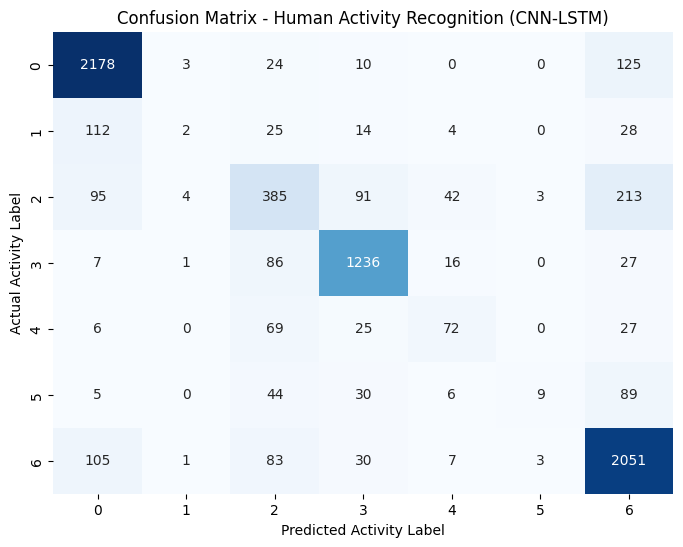

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Split data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training Data Shape: {X_train.shape}")
print(f"Testing Data Shape: {X_test.shape}")

# 2. Train the CNN-LSTM Model
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_test, y_test),
    verbose=1
)
model.save('har_cnn_lstm_model.h5')
print("Model saved successfully!")

# 3. Evaluate and Predict on Test Set
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# 4. Generate Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 5. Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Human Activity Recognition (CNN-LSTM)')
plt.xlabel('Predicted Activity Label')
plt.ylabel('Actual Activity Label')
plt.show()